In [31]:
# Import libraries

import pandas as pd
import numpy as np

In [32]:
from google.colab import files
uploaded=files.upload()

Saving diabetes.csv to diabetes (1).csv


In [33]:
# Load the dataset

df = pd.read_csv("diabetes.csv")

print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [34]:
# Check the dataset

print(df.shape)
print(df.info())

(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [35]:
# Check the outcome

print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


In [36]:
# Check zero values

print((df == 0).sum())

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [37]:
# Replace invalid zeros with missing values

columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for column in columns:
    df[column] = df[column].replace(0, np.nan)

print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [38]:
# Separate input and output

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print(X.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0      NaN  33.6   
1            1     85.0           66.0           29.0      NaN  26.6   
2            8    183.0           64.0            NaN      NaN  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  


In [39]:
# Import train-test split

from sklearn.model_selection import train_test_split

In [40]:
# Split the data into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(614, 8)
(154, 8)


In [41]:
# Import median imputer

from sklearn.impute import SimpleImputer

In [42]:
# Fill missing values using median

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing values filled")

Missing values filled


In [44]:
# Import StandardScaler

from sklearn.preprocessing import StandardScaler

In [45]:
# Scale the data

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data scaled")

Data scaled


In [46]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

In [47]:
# Train the Logistic Regression model

model = LogisticRegression(class_weight="balanced")

model.fit(X_train, y_train)

print("Model trained")

Model trained


In [48]:
# Make predictions

y_pred = model.predict(X_test)

print(y_pred)

[0 0 0 0 1 1 0 1 1 1 0 1 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 1
 0 1 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0
 0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 0
 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 1 1 0 0 1 1 0 0 0 0 1 0 0 0 0
 1 1 0 1 0 0]


In [49]:
# Import evaluation functions

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

In [50]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7012987012987013


In [51]:
# Calculate precision

precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.5652173913043478


In [52]:
# Calculate recall

recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.7090909090909091


In [53]:
# Calculate F1-score

f1 = f1_score(y_test, y_pred)

print("F1-score:", f1)

F1-score: 0.6290322580645161


In [54]:
# Calculate ROC-AUC

y_probability = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8214876033057851


In [55]:
# Show all evaluation results

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.7012987012987013
Precision: 0.5652173913043478
Recall: 0.7090909090909091
F1-score: 0.6290322580645161
ROC-AUC: 0.8214876033057851


In [56]:
# Calculate confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[69 30]
 [16 39]]


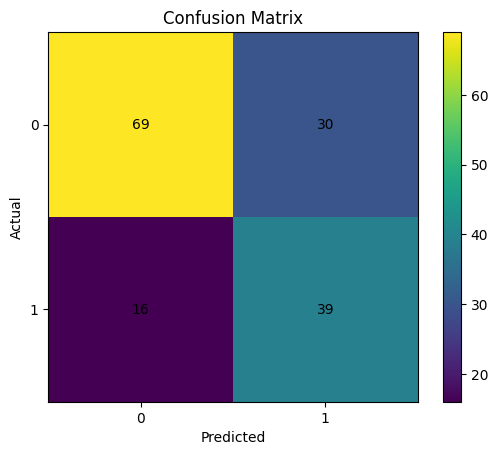

In [62]:
# Display confusion matrix

import matplotlib.pyplot as plt

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1])
plt.yticks([0, 1])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()

plt.show()

In [58]:
# Check model coefficients

features = X.columns
coefficients = model.coef_[0]

for feature, coefficient in zip(features, coefficients):
    print(feature, ":", coefficient)

Pregnancies : 0.23799556822538429
Glucose : 1.1340158658008594
BloodPressure : -0.16815158124212304
SkinThickness : 0.06916551250508442
Insulin : -0.13556038248234545
BMI : 0.7136226539196903
DiabetesPedigreeFunction : 0.23957772656239112
Age : 0.44309389209304745


In [59]:
# Create coefficient table

result = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefficients
})

print(result)

                    Feature  Coefficient
0               Pregnancies     0.237996
1                   Glucose     1.134016
2             BloodPressure    -0.168152
3             SkinThickness     0.069166
4                   Insulin    -0.135560
5                       BMI     0.713623
6  DiabetesPedigreeFunction     0.239578
7                       Age     0.443094


In [60]:
# Sort coefficients

result = result.sort_values(
    by="Coefficient",
    ascending=False
)

print(result)

                    Feature  Coefficient
1                   Glucose     1.134016
5                       BMI     0.713623
7                       Age     0.443094
6  DiabetesPedigreeFunction     0.239578
0               Pregnancies     0.237996
3             SkinThickness     0.069166
4                   Insulin    -0.135560
2             BloodPressure    -0.168152


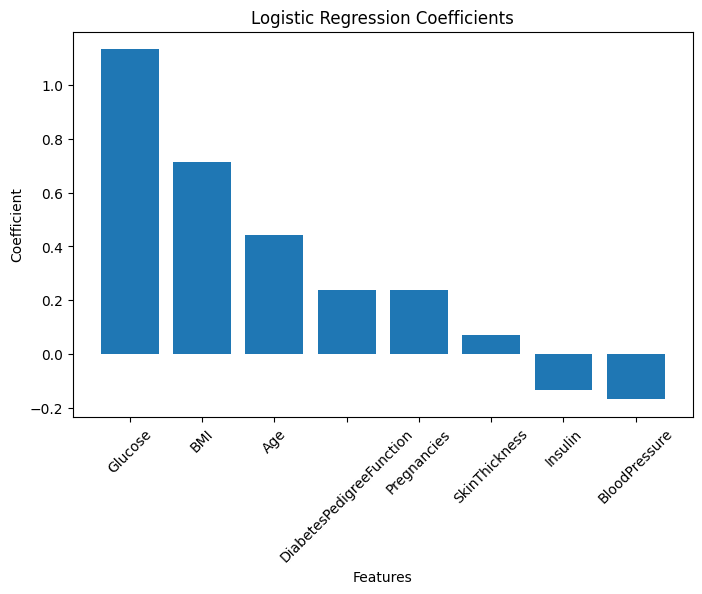

In [61]:
# Display coefficient graph

plt.figure(figsize=(8,5))

plt.bar(result["Feature"], result["Coefficient"])

plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.title("Logistic Regression Coefficients")

plt.show()

Conclusion:

The project predicts diabetes using Logistic Regression and the Pima Indians Diabetes dataset. The model was evaluated using accuracy, precision, recall, F1-score and ROC-AUC. Glucose and BMI showed strong positive coefficients. This project helped me understand how Logistic Regression can be used for classification. The model is only for learning purposes and is not suitable for medical diagnosis.